
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona MX- Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

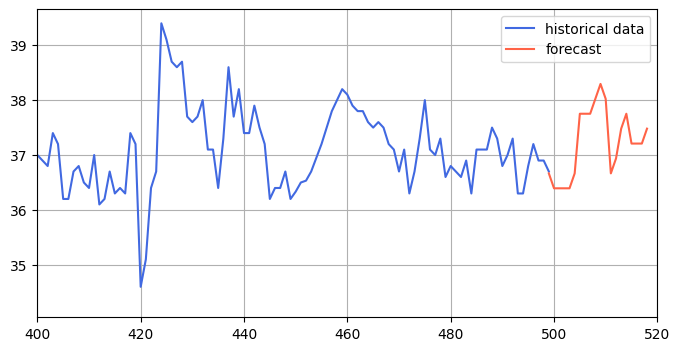

**Fuente**: https://towardsdatascience.com/how-to-effectively-forecast-time-series-with-amazons-new-time-series-forecasting-model-9e04d4ccf67e

El objetivo de este documento es explorar estrategias para realizar pronósticos sobre series de tiempo, basadas únicamente en la secuencia de valores. Bajo la premisa de que **los valores futuros de la serie deben ser similares a los pasados**, estas estrategias pueden brindar resultados aceptables.

Considerando que se han observado valores de la serie de tiempo hasta un instante $t$, esto es, $x_1, x_2, \ldots, x_t$ son conocidos, buscamos estimar el valor futuro $x_{t+1}$:

$$\color{blue}{x_{t+1} = f(x_t, x_{t-1}, x_{t-2}, \ldots)}$$


# Pronósticos con promedio móvil

El pronóstico por promedio móvil de $x_{t+1}$, de orden $k$, se obtiene promediando las últimas $k$ observaciones registradas:

$$\widehat{x}_{t+1} = \frac{x_t+x_{t-1}+\cdots x_{t-k+1}}{k} = \frac{1}{k}\sum_{i=0}^{k-1}x_{t-i}$$




## Ejemplo 1

La siguiente serie de tiempo contiene $5$ observaciones.

* Pronosticamos la sexta con el promedio de las últimas 2, o dicho de otra forma, aplicando promedio móvil de orden 2:  



In [ ]:
# Definimos la lista
X = [2, 9, 8, 5, 6]

# Calculamos el promedio de los últimos dos elementos
Xp = (X[4] + X[3]) / 2

# Mostramos el resultado
Xp

5.5

<Axes: >

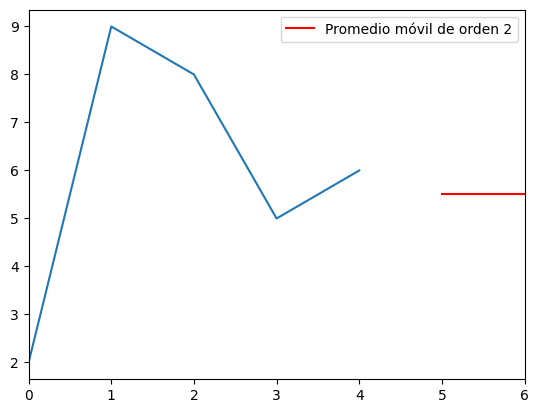

In [ ]:
X = pd.Series(X)
plt.xlim(0, 6)
plt.plot([5, 6], [Xp, Xp], 'r')
plt.legend(['Promedio móvil de orden 2'])
X.plot()

## Ejemplo 2

Consideremos un fragmento de la serie de tiempo de manchas solares:

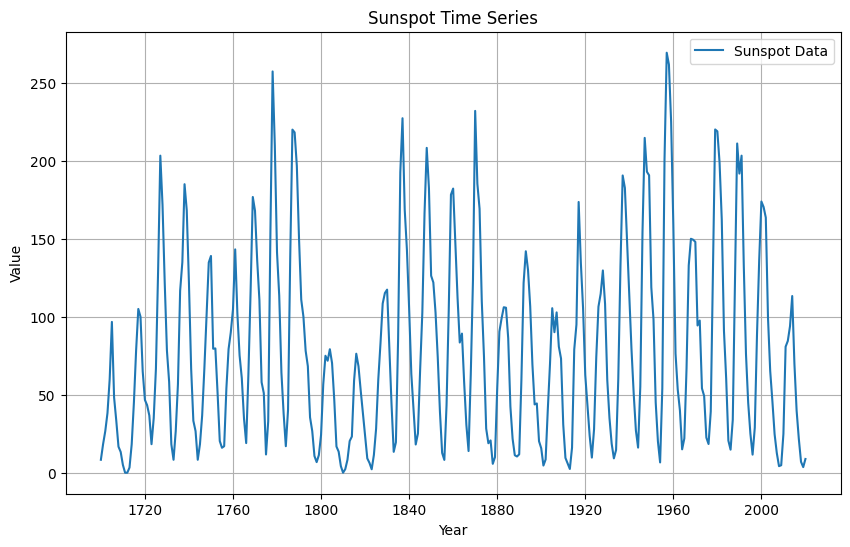

In [ ]:
sunspot = pd.read_csv("sunspot2.0.csv", header=0, names=["x"])

# Crear un rango de años desde 1700 con la misma longitud que los datos
years = pd.date_range(start="1700", periods=len(sunspot), freq="YS")

# Asignar los años como índice
sunspot.index = years

plt.figure(figsize=(10, 6))
plt.plot(sunspot.index, sunspot["x"], label="Sunspot Data")
plt.title("Sunspot Time Series")
plt.xlabel("Year")
plt.ylabel("Value")
plt.legend()
plt.grid()
plt.show()

Limitemos a los datos posteriores a 1990:

<Axes: >

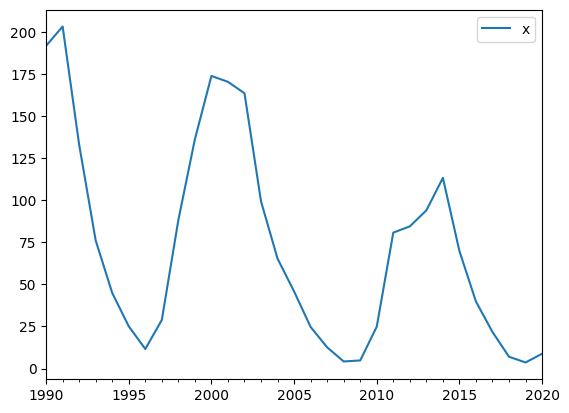

In [ ]:
sub_sunspot = sunspot.loc[sunspot.index >= "1990"]
sub_sunspot.plot()

Evaluamos el promedio móvil:

**Nota**: el orden busca abarcar un ciclo de alrededor de 11 años, aunque es un tanto arbitrario.

In [ ]:
# promediamos los 11 registros más recientes
ma_sunspot = sub_sunspot[-11:].mean()
ma = ma_sunspot.values[0]
ma

49.83636363636363

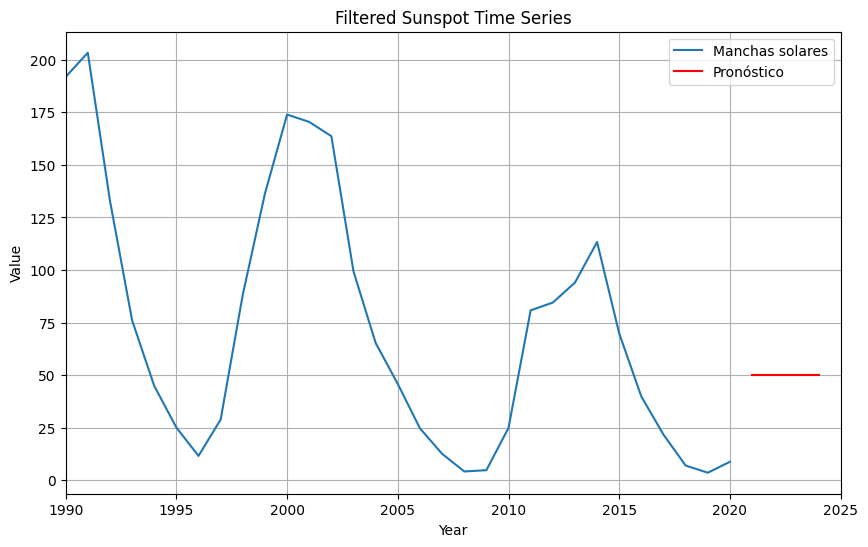

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(sub_sunspot.index.year, sub_sunspot["x"], label="Manchas solares")

# mostramos el pronóstico
plt.plot(np.arange(2021, 2025), [ma for _ in np.arange(2021, 2025)], 'r', label="Pronóstico")

plt.title("Filtered Sunspot Time Series")
plt.xlabel("Year")
plt.ylabel("Value")
plt.xlim(1990, 2025)  # Ajustar el límite en x
plt.legend()
plt.grid()
plt.show()

**¿Qué tan exacto resulta emplear el promedio móvil para hacer pronósticos?**

Vamos a aplicar el promedio móvil sobre los datos históricos y a comparar los valores estimados contra lso registrados.

In [ ]:
k = 11
ma_sunspot = sub_sunspot.rolling(k).mean()
ma_sunspot

,x
1990-01-01,NaN
1991-01-01,NaN
1992-01-01,NaN
1993-01-01,NaN
1994-01-01,NaN
1995-01-01,NaN
1996-01-01,NaN
1997-01-01,NaN
1998-01-01,NaN
1999-01-01,NaN


Comparemos el valor del promedio móvil contra los valores registrados:

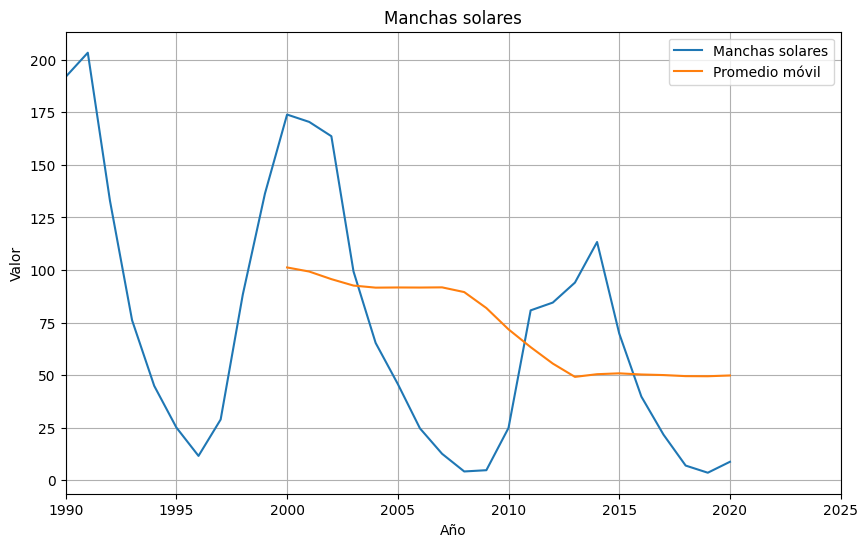

In [ ]:
ma_sunspot = sub_sunspot.rolling(k).mean()

plt.figure(figsize=(10, 6))
plt.plot(sub_sunspot.index.year, sub_sunspot["x"], label="Manchas solares")

# mostramos la estimación con promedio móvil
plt.plot(ma_sunspot.index.year, ma_sunspot['x'], label="Promedio móvil")

plt.title("Manchas solares")
plt.xlabel("Año")
plt.ylabel("Valor")
plt.xlim(1990, 2025)  # Ajustar el límite en x
plt.legend()
plt.grid()
plt.show()


* El promedio móvil ignora (aplasta) las variaciones cíclicas en la serie.

* **El promedio móvil asigna la misma importancia a cada uno de los registros históricos que combina para hacer la estimación**, ¿no deberían tener más peso los más receintes que los más antiguos?



# Suavizamiento exponencial

Una alternativa para realizar pronósticos es el suavizado exponencial que veremos en las siguientes celdas.

* Suponemos que la serie de tiempo se construye a partir del siguiente modelo:

$$x_t = \mu_t+e_t$$

siendo $\mu_t$ la tendencia de la serie (desconocida) y $e_t$ el ruido.

* Aproximamos la tendencia con el valor
    $$u_t \approx \mu_t$$

* Para algún valor, $\alpha \in [0, \; 1]$, consideramos pronosticar la tendencia mediante u. compromiso entre el valor anterior de la tendencia y el valor registrado en la serie de tiempo:

$$\color{blue}{u_{t+1} = \alpha x_t + (1-\alpha)u_{t}}$$

aquí, $x_t$ es el valor registrado de la serie de tiempo y $u_t$ es el valor de la tendencia, ambos en el instante $t$.  

El parámetro $\alpha$ permite establecer un compromiso entre el valor más reciente de la serie, $x_t$, y el valor más reciente de la estimación de la media, $u_t$ (inicialmente en cero).

**Ejemplo**

Para ejemplificar, supón que:

* $u_t$ es una aproximación a los **ingresos de un retailer** en un mes (puedes suponer que $u_t$ es el pronóstico de ingresos para *abril* obtenidos con los datos de marzo).

* El valor $x_t$, son los ingresos realmente observados en el mes de abril.

* Entonces $u_{t+1}$ sería el pronóstico de ingresos del retailer en *mayo* tomando un compromiso entre el pronóstico realizado para abril y el valor de ingresos realmente registrado en abril.
* Si $\alpha = 0.5$ entonces aproximamos con el promedio de ambos valores:

$$u_{t+1} = \frac{u_t+x_t}{2}$$

## Ejemplo 3

Las siguientes celdas muestran la aplicación del suavizado exponencial a una serie de tiempo.

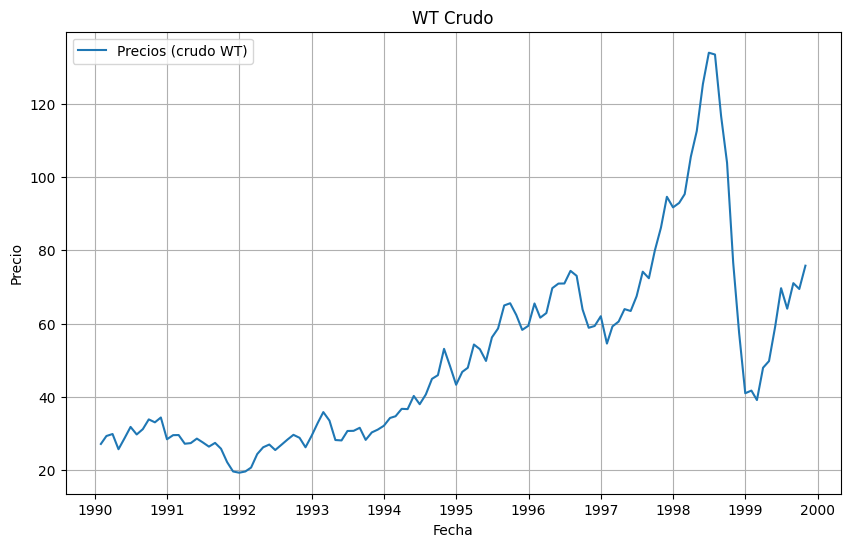

In [ ]:
wtcrude = pd.read_csv("wtcrude.csv", header=0)

# Crear un rango de fechas desde 1990 con frecuencia mensual
dates = pd.date_range(start="1990-01", periods=len(wtcrude), freq="ME")

# Asignar el rango de fechas como índice
wtcrude.index = dates

# Graficar la serie de tiempo
plt.figure(figsize=(10, 6))
plt.plot(wtcrude.index, wtcrude.iloc[:, 0], label="Precios (crudo WT)")  # Ajustar al nombre de la columna si es diferente
plt.title("WT Crudo")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.legend()
plt.grid()
plt.show()


El suavizado exponencial puede aplicarse con la librería `statsmodels`:

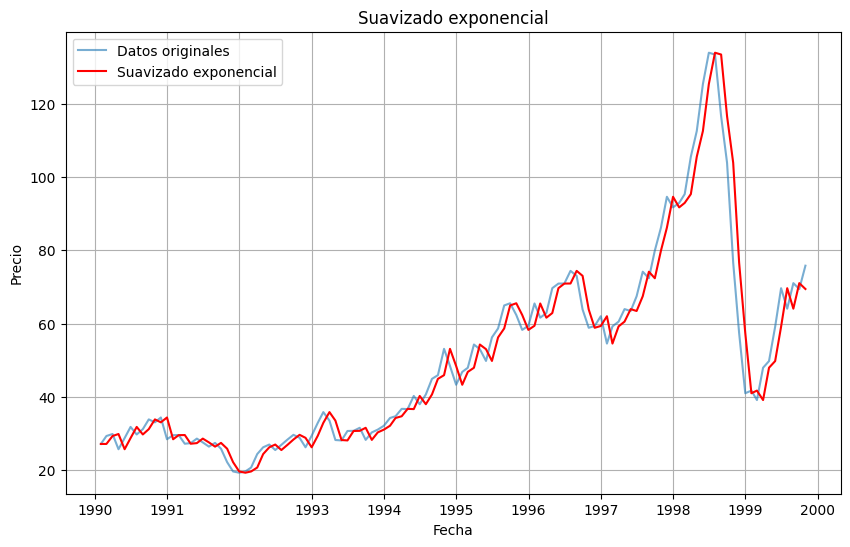

In [ ]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Aplicar el suavizado exponencial simple
model = SimpleExpSmoothing(wtcrude.iloc[:, 0])  # Seleccionar la primera columna

#wtcrude_se = model.fit(smoothing_level=0.5)
wtcrude_se = model.fit(optimized=True)

# Graficar los resultados
plt.figure(figsize=(10, 6))
plt.plot(wtcrude.index, wtcrude.iloc[:, 0], label="Datos originales", alpha=0.6)
plt.plot(wtcrude.index, wtcrude_se.fittedvalues, label="Suavizado exponencial", color="red")
plt.title("Suavizado exponencial")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.legend()
plt.grid()
plt.show()

Comparamos con el promedio móvil (de orden 4, no optimizado).

In [ ]:
ma_wt = wtcrude.rolling(4).mean()
ma_wt

,x
1990-01-31,NaN
1990-02-28,NaN
1990-03-31,NaN
1990-04-30,28.0400
1990-05-31,28.4400
...,...
1999-06-30,56.6525
1999-07-31,60.6800
1999-08-31,65.9975
1999-09-30,68.5725


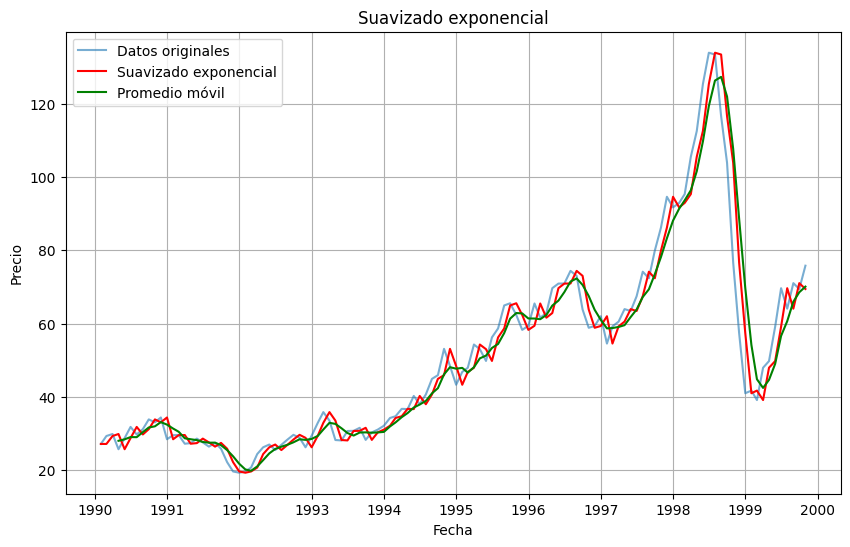

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(wtcrude.index, wtcrude.iloc[:, 0], label="Datos originales", alpha=0.6)
plt.plot(wtcrude.index, wtcrude_se.fittedvalues, label="Suavizado exponencial", color="red")
plt.plot(ma_wt.index, ma_wt.iloc[:, 0], label="Promedio móvil", color="g")
plt.plot()
plt.title("Suavizado exponencial")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.legend()
plt.grid()
plt.show()

Tenemos dos modelos, **¿cómo los comparamos cuantitativamente?**

**¿Por qué se denomina suavizado exponencial?**

El nombre de *suavizado exponencial* se explica a partir del proceso con el que se generan los pronósticos:

* $u_1 = x_1$
* $u_2 = \alpha x_1+(1-\alpha)u_1 \\ \;\;\;\;= \alpha x_1+(1-\alpha)x_1 \\ \;\;\;\;= x_1$
* $u_3 = \alpha x_2+(1-\alpha)u_2 \\ \;\;\;\;= \alpha x_2+(1-\alpha)x_1$

* $u_4 = \alpha x_3+\alpha(1-\alpha)x_2+(1-\alpha)^2x_1$
* $u_5 = \alpha x_4+\alpha(1-\alpha)x_3+\alpha(1-\alpha)^2x_2+(1-\alpha)^3x_1$

Observa que los pronósticos úeden considerarse como un promedio pesado de los valores observados de la serie, en el que los más recientes tienen mayor peso que los más antiguos.

La gráfica de la siguiente celda representa el peso que se asigna a las 4 valores observados más recientes para $\alpha=0.7$.


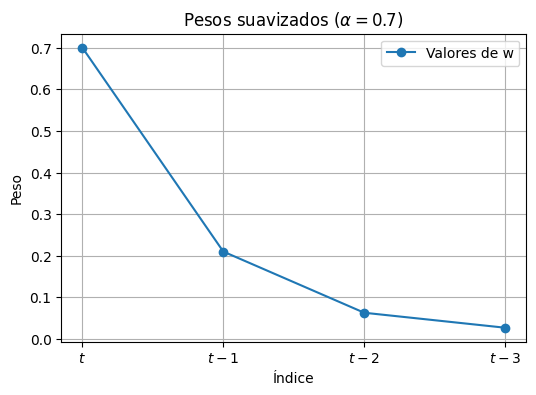

In [ ]:
# Definir los valores
a = 0.7
ca = 1 - a
w = [a, a * ca, a * ca**2, ca**3]

ticks = ["$t$", "$t-1$", "$t-2$", "$t-3$"]

# Graficar los valores
plt.figure(figsize=(6, 4))
plt.plot(w, marker='o', linestyle='-', label="Valores de w")
plt.title("Pesos suavizados ($\\alpha = 0.7$)")
plt.xlabel("Índice")
plt.ylabel("Peso")
plt.xticks(range(len(w)), ticks)  # Modificar los ticks del eje x
plt.grid()
plt.legend()
plt.show()

Los pesos decaen *exponencialmente*.

**Nota:**

* Ni el promedio móvil ni el suavizado exponencial consideran variaciones estacionales en la serie de tiempo.


# Holt Winters

<font color="blue">Considera una serie con una componente estacional y un periodo de $m$ registros.</font>

* Por ejemplo, las ventas de algún producto cuya demanda aumenta con las bajas temperaturas y disminuye con el calor. El periodo sería de un año: $m = 12$ si se registran las ventas mensualmente, o $m = 365$ si se registran diariamente.   

* En esos casos, las estrategias de pronóstico mediante promedio móvil o suavizado exponencial no explotan la información de la **estacionalidad de la serie**.

Buscando superar esta limitación, podemos explorar una alternativa para los pronósticos como el método Holt-Winters, el cual se basa en la construcción de 3 series paralelas a la original:

* **Tendencia promedio**: $u_t = \alpha(x_t-s_{t-m})+(1-\alpha)(u_{t-1}+v_{t-1})$
* **Tasa de cambio**: $v_t = \beta (u_t-u_{t-1})+(1-\beta)v_{t-1} $
* **Estacionalidad**: $s_t = \gamma (x_t-u_{t-1})+(1-\gamma)s_{t-m}$

Siendo $m$ el periodo de la serie.

Suponiendo que el registro más reciente es en el instante $n$, los valores estimados son:

* Para $t\in [m,n]$ (fase de aprendizaje, modelo aplicado sobre valores históricos):

$$\widehat{x}_t = u_{t-1}+v_{t-1}+s_{t-m}$$

* Mientras que para una **proyección** con un horizonte temporal de $l$ registros (posteriores a $n$):

$$\color{blue}{\widehat{x}_{n+l} = u_n+mv_n+s_{n+l-ml'}}$$

siendo $l' = \lceil (l-1)/m \rceil + 1$.



## Ejemplo 4

Aplicando el filtro HoltWinters pronostiquemos las temperaturas mensuales en DFW para dos años:

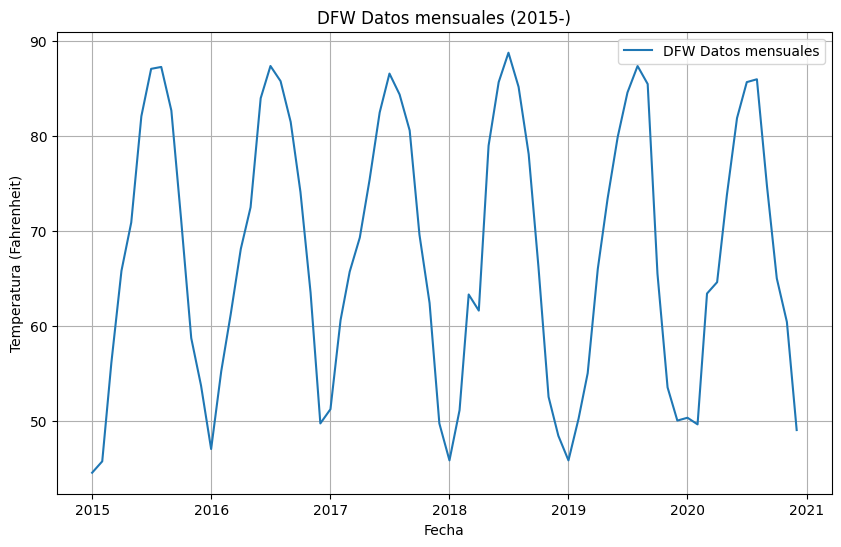

In [ ]:
dfw_mon = pd.read_csv("dfw_mon.csv")

# Crear un rango de fechas con frecuencia mensual comenzando en 1900-01-01
dates = pd.date_range(start="1900-01-01", periods=len(dfw_mon), freq="MS")

# Asignar el rango de fechas como índice
dfw_mon.index = dates

# Filtrar los datos a partir de 2015
dfw_mon_2015 = dfw_mon.loc["2015-01-01":]

# Graficar los datos filtrados
plt.figure(figsize=(10, 6))
plt.plot(dfw_mon_2015.index, dfw_mon_2015.iloc[:, 0], label="DFW Datos mensuales")  # Ajusta la columna si es necesario
plt.title("DFW Datos mensuales (2015-)")
plt.xlabel("Fecha")
plt.ylabel("Temperatura (Fahrenheit)")
plt.legend()
plt.grid()
plt.show()

Aplicamos Hotl-Winters para pronosticar un periodo de un año:

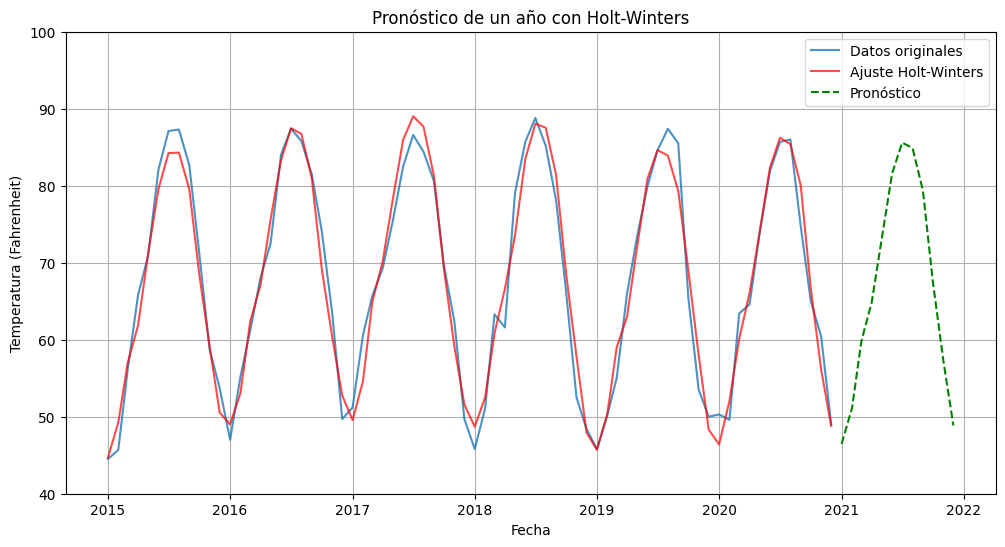

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Ajustar el modelo Holt-Winters (componente estacional aditivo)
model = ExponentialSmoothing(
    dfw_mon_2015.iloc[:, 0],  # Seleccionar la primera columna
    seasonal="additive",  # Ajustar estacionalidad aditiva
    seasonal_periods=12  # Frecuencia estacional (mensual)
)

fitted_model = model.fit(optimized=True)

#############################################
# Pronóstico para un año hacia adelante
forecast = fitted_model.forecast(steps=12)
#############################################

# Graficar los datos originales, el ajuste y el pronóstico
plt.figure(figsize=(12, 6))
plt.plot(dfw_mon_2015.index, dfw_mon_2015.iloc[:, 0], label="Datos originales", alpha=0.8)
plt.plot(fitted_model.fittedvalues, label="Ajuste Holt-Winters", color="red", alpha=0.7)
plt.plot(forecast.index, forecast, label="Pronóstico", color="green", linestyle="--")
plt.title("Pronóstico de un año con Holt-Winters")
plt.xlabel("Fecha")
plt.ylabel("Temperatura (Fahrenheit)")
plt.ylim((40, 100))
plt.legend()
plt.grid()
plt.show()


**Comparamos Holt Winters contra Suavizado Exponencial**

Separación entrenamiento y prueba:

In [ ]:
train = dfw_mon_2015.iloc[:-12] # todos excepto el último año para entrenamiento
test = dfw_mon_2015.iloc[-12:]  # dejamos los del último año para prueba

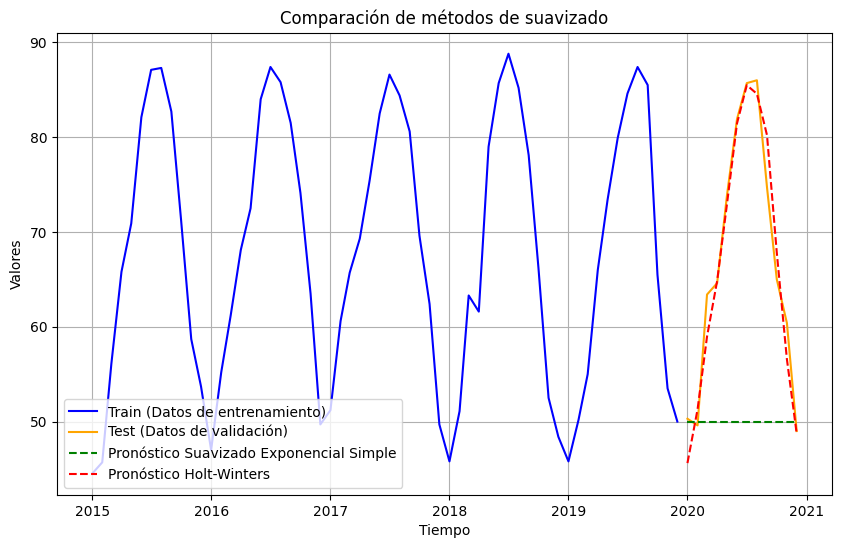

In [ ]:
# Ajustar el modelo de Suavizado Exponencial Simple
simple_model = SimpleExpSmoothing(train)  # Suavizado exponencial simple
fitted_simple = simple_model.fit(optimized=True)  # Ajustar modelo con optimización de alfa
simple_forecast = fitted_simple.forecast(steps=12)  # Pronóstico para los próximos 12 periodos

# Ajustar el modelo Holt-Winters (componente estacional aditiva)
hw_model = ExponentialSmoothing(
    train,
    seasonal="additive",  # Estacionalidad aditiva
    seasonal_periods=12   # Frecuencia estacional (mensual)
)
fitted_hw = hw_model.fit(optimized=True)  # Ajustar modelo Holt-Winters
hw_forecast = fitted_hw.forecast(steps=12)  # Pronóstico para los próximos 12 periodos

# Comparar pronósticos
plt.figure(figsize=(10, 6))
plt.plot(train.index, train, label="Train (Datos de entrenamiento)", color="blue")
plt.plot(test.index, test, label="Test (Datos de validación)", color="orange")
plt.plot(test.index[:12], simple_forecast, label="Pronóstico Suavizado Exponencial Simple", color="green", linestyle="--")
plt.plot(test.index[:12], hw_forecast, label="Pronóstico Holt-Winters", color="red", linestyle="--")
plt.legend()
plt.title("Comparación de métodos de suavizado")
plt.xlabel("Tiempo")
plt.ylabel("Valores")
plt.grid()
plt.show()


# <font color="red">Actividad</font>

Considera la siguiente serie de tiempo:

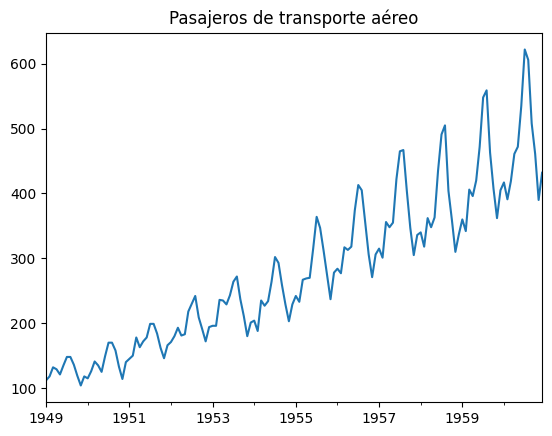

In [ ]:
from statsmodels.datasets import get_rdataset

data = get_rdataset("AirPassengers").data

# Convertir a DataFrame y establecer índice temporal
air_passengers = pd.Series(data['value'].values, index=pd.date_range(start="1949-01", periods=len(data), freq="ME"))
air_passengers.plot(title="Pasajeros de transporte aéreo", legend=False)
plt.show()

In [ ]:
air_passengers.tail()

,0
1960-08-31,606
1960-09-30,508
1960-10-31,461
1960-11-30,390
1960-12-31,432


1. Separa los datos en dos subconjuntos. El primero, de entrenamiento, debe corresponder a los datos previos a 1960. El segundo, de prueba, debe contener las observaciones de 1960.
2. Modela la serie empleando la técnica de Holt-Winters.
  * Utiliza solamente los datos de entrenamiento para ajustar el modelo.
  * Considera que el modelo multiplicativo explica mejor esta serie que el aditivo.
3. Pronostica los valores del año 1960 y compara los valores pronosticados contra los registrados,
  * ¿Cuál es el error absoluto promedio?
  * ¿Cuál es el error absoluto porcentual promedio?
4. Modifica el ajuste para considerar que el modelo es aditivo en lugar de multiplicativo, ¿los reesultados empeoran o mejoran?.


# Separar la serie en entrenamiento (datos previos a 1960) y prueba (observaciones de 1960)


In [ ]:
train = air_passengers[air_passengers.index.year < 1960]
test = air_passengers[air_passengers.index.year == 1960]

print("Datos de entrenamiento:")
print(train.tail())
print("\nDatos de prueba:")
print(test)


Datos de entrenamiento:
1959-08-31    559
1959-09-30    463
1959-10-31    407
1959-11-30    362
1959-12-31    405
Freq: ME, dtype: int64

Datos de prueba:
1960-01-31    417
1960-02-29    391
1960-03-31    419
1960-04-30    461
1960-05-31    472
1960-06-30    535
1960-07-31    622
1960-08-31    606
1960-09-30    508
1960-10-31    461
1960-11-30    390
1960-12-31    432
Freq: ME, dtype: int64


# Ajuste del modelo usando tendencia aditiva y estacionalidad multiplicativa (con periodicidad de 12 meses)


In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model_mul = ExponentialSmoothing(train, trend="add", seasonal="mul", seasonal_periods=12).fit()



# Pronosticar los valores para el año 1960 (cantidad de observaciones en test)
forecast_mul = model_mul.forecast(len(test))

print("Pronósticos (Multiplicativo):")
print(forecast_mul)


# Calcular el error absoluto medio (MAE) y el error porcentual absoluto medio (MAPE)


In [ ]:
import numpy as np

mae_mul = np.mean(np.abs(test - forecast_mul))
mape_mul = np.mean(np.abs((test - forecast_mul) / test)) * 100

print("Modelo Multiplicativo:")
print("MAE =", mae_mul)
print("MAPE =", mape_mul, "%")


Modelo Multiplicativo:
MAE = 10.299694207748567
MAPE = 2.2068259147480394 %


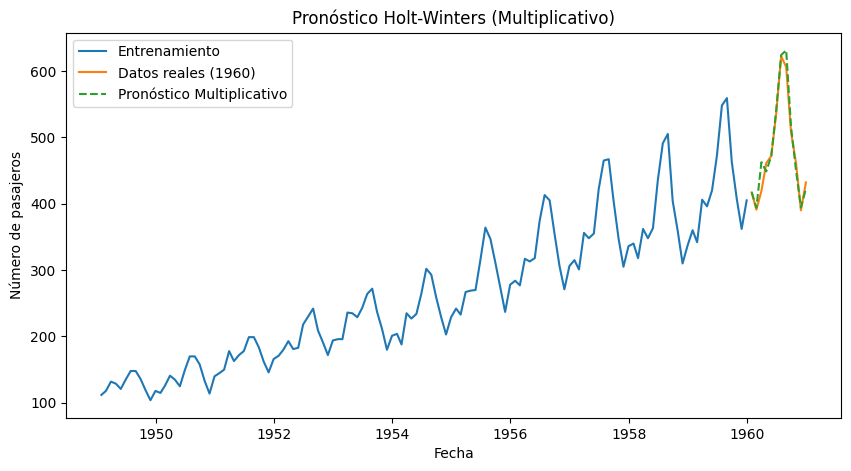

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(train.index, train, label="Entrenamiento")
plt.plot(test.index, test, label="Datos reales (1960)")
plt.plot(test.index, forecast_mul, label="Pronóstico Multiplicativo", linestyle="--")
plt.title("Pronóstico Holt-Winters (Multiplicativo)")
plt.xlabel("Fecha")
plt.ylabel("Número de pasajeros")
plt.legend()
plt.show()


# Ajuste del modelo aditivo


In [ ]:
model_add = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit()
forecast_add = model_add.forecast(len(test))

# Calcular métricas de error para el modelo aditivo


In [ ]:
mae_add = np.mean(np.abs(test - forecast_add))
mape_add = np.mean(np.abs((test - forecast_add) / test)) * 100

print("Modelo Aditivo:")
print("MAE =", mae_add)
print("MAPE =", mape_add, "%")


Modelo Aditivo:
MAE = 13.380462475074248
MAPE = 2.802823947659527 %


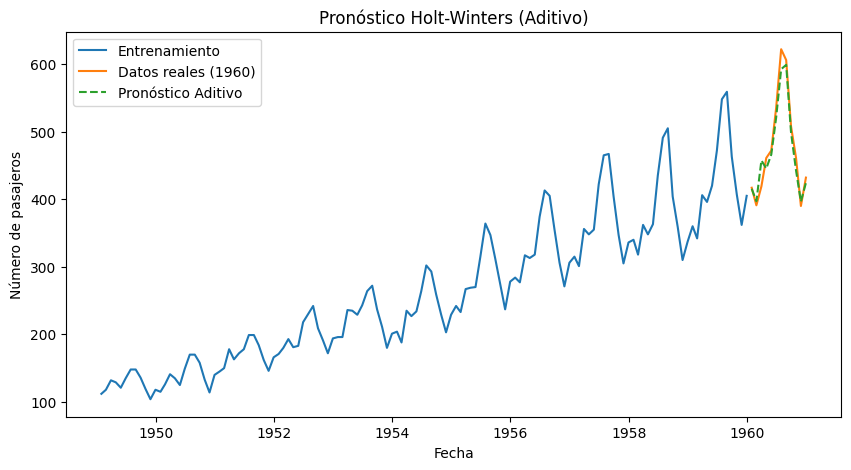

Comparación de modelos:
Multiplicativo: MAE = 10.299694207748567 , MAPE = 2.2068259147480394 %
Aditivo:        MAE = 13.380462475074248 , MAPE = 2.802823947659527 %


In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(train.index, train, label="Entrenamiento")
plt.plot(test.index, test, label="Datos reales (1960)")
plt.plot(test.index, forecast_add, label="Pronóstico Aditivo", linestyle="--")
plt.title("Pronóstico Holt-Winters (Aditivo)")
plt.xlabel("Fecha")
plt.ylabel("Número de pasajeros")
plt.legend()
plt.show()

print("Comparación de modelos:")
print("Multiplicativo: MAE =", mae_mul, ", MAPE =", mape_mul, "%")
print("Aditivo:        MAE =", mae_add, ", MAPE =", mape_add, "%")
